In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os, json, time
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.base import clone

FROZEN_DIR = "/content/drive/MyDrive/frozen_dataset"
PIPE_DIR = "/content/drive/MyDrive/day22/final_pipeline_v1"
TARGET_COLUMN = "soc_percent"
RAW_FEATURES = ["voltage_v", "current_a", "cell_temp_c", "power_w", "ambient_temp_c"]
CHARGE_FEATURES = ["voltage_v", "current_a", "cell_temp_c", "ambient_temp_c"]
CHARGE_TARGET = "remaining_charge_time_s"
os.makedirs("final_validation", exist_ok=True)

cfg = json.load(open(f"{PIPE_DIR}/frozen_config.json"))
df_train = pd.read_csv(f"{FROZEN_DIR}/dataset_v1_train.csv")
df_test = pd.read_csv(f"{FROZEN_DIR}/dataset_v1_test.csv")
assert list(df_train.shape) == cfg["train_shape"] and list(df_test.shape) == cfg["test_shape"], "Dataset changed since the Day 22 freeze!"
assert sorted(df_test["file_id"].unique()) == cfg["test_file_ids"], "Test files differ from the Day 22 freeze!"
final_pipe = joblib.load(f"{PIPE_DIR}/soc_final_pipeline.joblib")
print("Frozen model:", cfg["chosen_model"], "| train", df_train.shape, "| test", df_test.shape)

def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}

Frozen model: RandomForest (tuned) | train (5028, 7) | test (328, 7)


In [6]:
y_tr, y_te = df_train[TARGET_COLUMN], df_test[TARGET_COLUMN]
lin = LinearRegression().fit(df_train[RAW_FEATURES], y_tr)
mean_b = DummyRegressor().fit(df_train[RAW_FEATURES], y_tr)

pred_tr = {"Mean baseline": mean_b.predict(df_train[RAW_FEATURES]),
           "Linear (simple baseline)": np.clip(lin.predict(df_train[RAW_FEATURES]), 0, 100),
           "FROZEN FINAL": np.clip(final_pipe.predict(df_train[RAW_FEATURES]), 0, 100)}
pred_te = {"Mean baseline": mean_b.predict(df_test[RAW_FEATURES]),
           "Linear (simple baseline)": np.clip(lin.predict(df_test[RAW_FEATURES]), 0, 100),
           "FROZEN FINAL": np.clip(final_pipe.predict(df_test[RAW_FEATURES]), 0, 100)}
rows = []
for k in pred_te:
    tr, te = metrics(y_tr, pred_tr[k]), metrics(y_te, pred_te[k])
    rows.append({"model": k, "train_MAE": tr["MAE"], "test_MAE": te["MAE"], "test_RMSE": te["RMSE"], "test_R2": te["R2"],
                 "gap_%": 100 * (te["MAE"] - tr["MAE"]) / max(tr["MAE"], 1e-9)})
val = pd.DataFrame(rows).set_index("model")
print("===== FINAL VALIDATION (test files, SOC %) =====")
print(val.round(4).to_string())
val.to_csv("final_validation/final_validation.csv")

fin, base = val.loc["FROZEN FINAL"], val.loc["Linear (simple baseline)"]
print(f"\nFrozen vs Linear: MAE {fin.test_MAE:.3f} vs {base.test_MAE:.3f} | RMSE {fin.test_RMSE:.3f} vs {base.test_RMSE:.3f} | R2 {fin.test_R2:.3f} vs {base.test_R2:.3f}")
print("Overfitting flag (train-test gap > 50%):", "YES" if fin["gap_%"] > 50 else "no")

===== FINAL VALIDATION (test files, SOC %) =====
                          train_MAE  test_MAE  test_RMSE  test_R2      gap_%
model                                                                       
Mean baseline               27.2882   28.9281    32.1916  -0.0328     6.0094
Linear (simple baseline)     5.8696   18.1044    25.1635   0.3689   208.4443
FROZEN FINAL                 1.5900   27.7253    37.7077  -0.4171  1643.7430

Frozen vs Linear: MAE 27.725 vs 18.104 | RMSE 37.708 vs 25.163 | R2 -0.417 vs 0.369
Overfitting flag (train-test gap > 50%): YES


In [7]:
t0 = time.perf_counter(); clone(final_pipe).fit(df_train[RAW_FEATURES], y_tr); fit_s = time.perf_counter() - t0

def batch_time(fn, df, reps=5):
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(df); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

def single_row_ms(fn, df, n=200):
    ts = []
    for i in range(min(n, len(df))):
        r = df.iloc[[i]]; t0 = time.perf_counter(); fn(r); ts.append(time.perf_counter() - t0)
    return 1000 * float(np.median(ts))

fin_fn = lambda d: np.clip(final_pipe.predict(d[RAW_FEATURES]), 0, 100)
lin_fn = lambda d: lin.predict(d[RAW_FEATURES])
fin_batch, lin_batch = batch_time(fin_fn, df_test), batch_time(lin_fn, df_test)
fin_one, lin_one = single_row_ms(fin_fn, df_test), single_row_ms(lin_fn, df_test)
joblib.dump(lin, "final_validation/_lin.joblib")
size_final = os.path.getsize(f"{PIPE_DIR}/soc_final_pipeline.joblib") / 1e6
size_lin = os.path.getsize("final_validation/_lin.joblib") / 1e6
os.remove("final_validation/_lin.joblib")

perf = pd.DataFrame({
    "batch_predict_s": [fin_batch, lin_batch],
    "rows_per_s": [len(df_test) / fin_batch, len(df_test) / lin_batch],
    "single_row_ms": [fin_one, lin_one],
    "model_size_MB": [size_final, size_lin]}, index=["FROZEN FINAL", "Linear (simple baseline)"])
print(f"Training time of frozen pipeline: {fit_s:.2f} s")
print(f"===== SOFTWARE PERFORMANCE (test batch = {len(df_test)} rows) =====")
print(perf.round(5).to_string())
perf.to_csv("final_validation/software_performance.csv")

Training time of frozen pipeline: 2.15 s
===== SOFTWARE PERFORMANCE (test batch = 328 rows) =====
                          batch_predict_s    rows_per_s  single_row_ms  model_size_MB
FROZEN FINAL                      0.09936    3301.03897       89.64362        6.13745
Linear (simple baseline)          0.00218  150138.19122        1.28738        0.00093


                          test_MAE  test_RMSE  test_R2  single_row_ms  size_MB  MAE_improvement_%  latency_x     size_x
Linear (simple baseline)   18.1044    25.1635   0.3689         1.2874   0.0009             0.0000     1.0000     1.0000
FROZEN FINAL               27.7253    37.7077  -0.4171        89.6436   6.1374           -53.1411    69.6326  6606.5124

VERDICT: Complexity NOT justified on test - recommend reverting to the simple baseline.


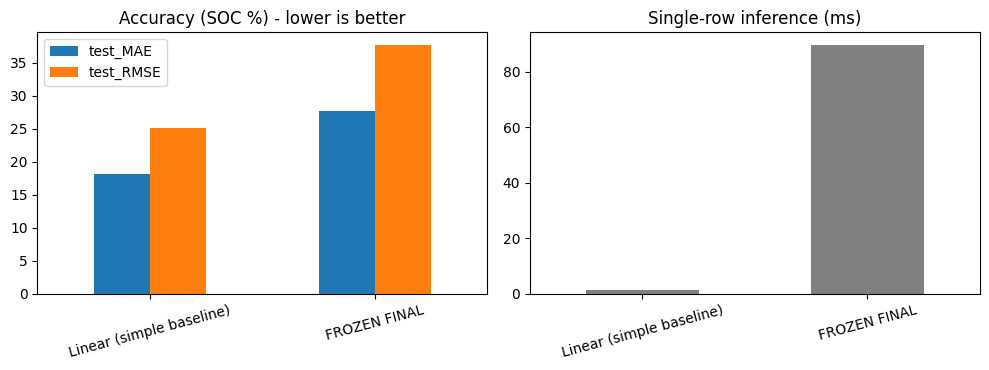

In [8]:
trade = pd.DataFrame({"test_MAE": [base.test_MAE, fin.test_MAE], "test_RMSE": [base.test_RMSE, fin.test_RMSE],
                      "test_R2": [base.test_R2, fin.test_R2], "single_row_ms": [lin_one, fin_one],
                      "size_MB": [size_lin, size_final]}, index=["Linear (simple baseline)", "FROZEN FINAL"])
trade["MAE_improvement_%"] = 100 * (base.test_MAE - trade["test_MAE"]) / base.test_MAE
trade["latency_x"] = trade["single_row_ms"] / lin_one
trade["size_x"] = trade["size_MB"] / size_lin
print(trade.round(4).to_string())
trade.to_csv("final_validation/accuracy_vs_complexity.csv")

mae_better, rmse_better = fin.test_MAE < base.test_MAE, fin.test_RMSE < base.test_RMSE
if cfg["chosen_model"].startswith("Linear"):
    verdict = "Final model IS the simple baseline - no complexity premium to justify."
elif mae_better and rmse_better:
    verdict = "Complexity justified: lower MAE AND lower RMSE than the simple baseline."
elif mae_better:
    verdict = "Mixed: wins MAE (typical error) but loses RMSE (large errors). Report both; keep Linear as documented fallback."
else:
    verdict = "Complexity NOT justified on test - recommend reverting to the simple baseline."
print("\nVERDICT:", verdict)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
trade[["test_MAE", "test_RMSE"]].plot(kind="bar", ax=ax[0], rot=15); ax[0].set_title("Accuracy (SOC %) - lower is better")
trade["single_row_ms"].plot(kind="bar", ax=ax[1], rot=15, color="gray"); ax[1].set_title("Single-row inference (ms)")
plt.tight_layout(); plt.savefig("final_validation/fig_tradeoff.png", dpi=150); plt.show()

Error by SOC band:
                n     MAE     max
SOC_band                        
0-15 (knee)   25  69.305  92.691
15-30         36  60.747  82.401
30-50         47  48.008  62.665
50-70         48  32.505  40.262
70-85         36  20.255  25.936
85-100       136   4.622  85.954

Worst 5 files:
                    n     MAE     max
file_id                             
25degC_C20DisCh  243  35.740  92.691
25degC_Charge8    22   7.897  85.954
25degC_Charge14   21   4.332  32.915
25degC_Charge15   21   4.096  47.316
25degC_Charge6    21   2.775  22.446

Worst band: 0-15 (knee) | worst file: 25degC_C20DisCh | top-1% rows carry 6% of squared error | RMSE/MAE = 1.36


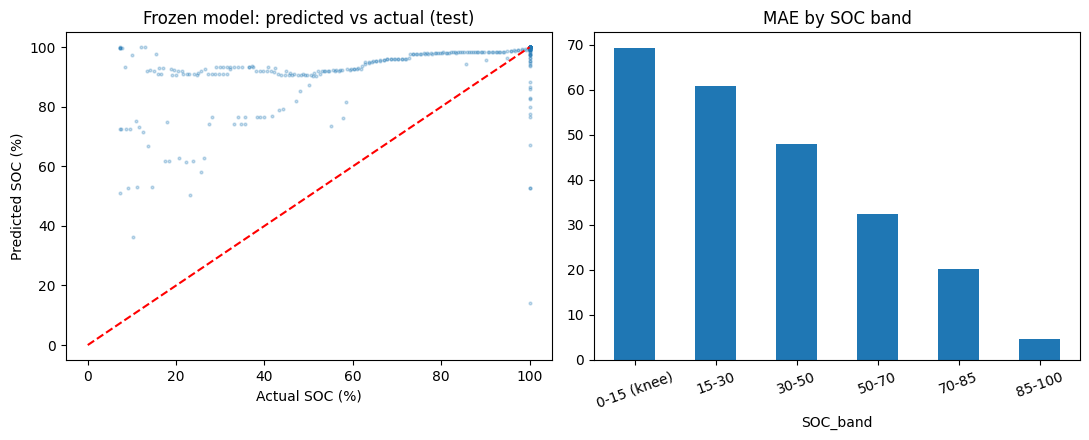

In [9]:
ev = df_test[["file_id", TARGET_COLUMN]].copy().reset_index(drop=True)
ev["pred"] = pred_te["FROZEN FINAL"]
ev["abs"] = (ev[TARGET_COLUMN] - ev["pred"]).abs(); ev["sq"] = (ev[TARGET_COLUMN] - ev["pred"]) ** 2
ev["SOC_band"] = pd.cut(ev[TARGET_COLUMN], [-0.01, 15, 30, 50, 70, 85, 100.01],
                        labels=["0-15 (knee)", "15-30", "30-50", "50-70", "70-85", "85-100"])
by_band = ev.groupby("SOC_band", observed=True)["abs"].agg(n="size", MAE="mean", max="max")
by_file = ev.groupby("file_id")["abs"].agg(n="size", MAE="mean", max="max").sort_values("MAE", ascending=False)
print("Error by SOC band:\n", by_band.round(3).to_string())
print("\nWorst 5 files:\n", by_file.head(5).round(3).to_string())
by_band.to_csv("final_validation/error_by_soc_band.csv"); by_file.to_csv("final_validation/error_by_file.csv")

worst_band, worst_file = by_band["MAE"].idxmax(), by_file.index[0]
top1 = ev["sq"].nlargest(max(1, int(0.01 * len(ev)))).sum() / ev["sq"].sum()
print(f"\nWorst band: {worst_band} | worst file: {worst_file} | top-1% rows carry {100*top1:.0f}% of squared error | RMSE/MAE = {fin.test_RMSE/fin.test_MAE:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(ev[TARGET_COLUMN], ev["pred"], s=4, alpha=.25); ax[0].plot([0, 100], [0, 100], "r--")
ax[0].set_xlabel("Actual SOC (%)"); ax[0].set_ylabel("Predicted SOC (%)"); ax[0].set_title("Frozen model: predicted vs actual (test)")
by_band["MAE"].plot(kind="bar", ax=ax[1], rot=20); ax[1].set_title("MAE by SOC band")
plt.tight_layout(); plt.savefig("final_validation/fig_final_error_analysis.png", dpi=150); plt.show()

In [10]:
charge = None
cpath = f"{PIPE_DIR}/charging_time_final_pipeline.joblib"
if os.path.exists(cpath):
    df_full = pd.read_csv(f"{FROZEN_DIR}/dataset_v1_full.csv")
    df_full["prog_time_td"] = pd.to_timedelta(df_full["prog_time"], errors="coerce")
    df_full = df_full.sort_values(["file_id", "prog_time_td"]).reset_index(drop=True)
    df_full["status_change"] = ((df_full["status"] != df_full["status"].shift(1)) |
                                (df_full["file_id"] != df_full["file_id"].shift(1)))
    df_full["segment_id"] = df_full["status_change"].cumsum()
    df_charge = df_full[df_full["status"] == "CHA"].copy()
    seg_end = df_charge.groupby("segment_id")["prog_time_td"].transform("max")
    df_charge[CHARGE_TARGET] = (seg_end - df_charge["prog_time_td"]).dt.total_seconds()
    df_charge = df_charge.dropna(subset=[CHARGE_TARGET] + CHARGE_FEATURES)
    c_tr = df_charge[df_charge["file_id"].isin(cfg["train_file_ids"])]
    c_te = df_charge[df_charge["file_id"].isin(cfg["test_file_ids"])]
    if len(c_te) > 0:
        charge_pipe = joblib.load(cpath)
        p_rf = np.maximum(charge_pipe.predict(c_te[CHARGE_FEATURES]), 0)
        p_mean = DummyRegressor().fit(c_tr[CHARGE_FEATURES], c_tr[CHARGE_TARGET]).predict(c_te[CHARGE_FEATURES])
        charge = {"RF frozen": metrics(c_te[CHARGE_TARGET], p_rf), "Mean baseline": metrics(c_te[CHARGE_TARGET], p_mean)}
        print(pd.DataFrame(charge).T.round(3).to_string())
        print(f"({c_te['file_id'].nunique()} test charge files, {len(c_te)} rows). If RF MAE is not below the mean baseline, report charging time as NOT validated.")
else:
    print("Charging-time artefact not found - skipped.")

                     MAE       RMSE     R2
RF frozen      26515.452  34932.466 -1.269
Mean baseline  27123.531  35448.398 -1.336
(5 test charge files, 153 rows). If RF MAE is not below the mean baseline, report charging time as NOT validated.


In [11]:
sub = f"""
Final SOC model: {cfg['chosen_model']} | features: {', '.join(RAW_FEATURES)} | clipped to [0,100].
Test: MAE {fin.test_MAE:.3f} | RMSE {fin.test_RMSE:.3f} | R2 {fin.test_R2:.4f} (train MAE {fin.train_MAE:.3f}, gap {fin['gap_%']:.0f}%).
Strongest simple baseline (Linear): MAE {base.test_MAE:.3f} | RMSE {base.test_RMSE:.3f} | R2 {base.test_R2:.4f}. Mean baseline MAE {val.loc['Mean baseline','test_MAE']:.2f}.
Runtime: fit {fit_s:.2f}s; single-row inference {fin_one:.3f} ms (Linear {lin_one:.3f} ms); {len(df_test)/fin_batch:,.0f} rows/s; model size {size_final:.2f} MB (Linear {size_lin:.4f} MB).
Trade-off: {verdict}
Errors: worst SOC band {worst_band}; worst file {worst_file}; top 1% of rows carry {100*top1:.0f}% of squared error; RMSE/MAE = {fin.test_RMSE/fin.test_MAE:.2f}.
Charging time: {'RF MAE %.0f s vs mean baseline %.0f s - low confidence' % (charge['RF frozen']['MAE'], charge['Mean baseline']['MAE']) if charge else 'not evaluated'}.
"""
print(sub)
open("final_validation/day23_written_submission.txt", "w").write(sub)

import shutil
shutil.copytree("final_validation", "/content/drive/MyDrive/day23/final_validation", dirs_exist_ok=True)
print(" Saved:", sorted(os.listdir("final_validation")))


Final SOC model: RandomForest (tuned) | features: voltage_v, current_a, cell_temp_c, power_w, ambient_temp_c | clipped to [0,100].
Test: MAE 27.725 | RMSE 37.708 | R2 -0.4171 (train MAE 1.590, gap 1644%).
Strongest simple baseline (Linear): MAE 18.104 | RMSE 25.163 | R2 0.3689. Mean baseline MAE 28.93.
Runtime: fit 2.15s; single-row inference 89.644 ms (Linear 1.287 ms); 3,301 rows/s; model size 6.14 MB (Linear 0.0009 MB).
Trade-off: Complexity NOT justified on test - recommend reverting to the simple baseline.
Errors: worst SOC band 0-15 (knee); worst file 25degC_C20DisCh; top 1% of rows carry 6% of squared error; RMSE/MAE = 1.36.
Charging time: RF MAE 26515 s vs mean baseline 27124 s - low confidence.

 Saved: ['accuracy_vs_complexity.csv', 'day23_written_submission.txt', 'error_by_file.csv', 'error_by_soc_band.csv', 'fig_final_error_analysis.png', 'fig_tradeoff.png', 'final_validation.csv', 'software_performance.csv']
